In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


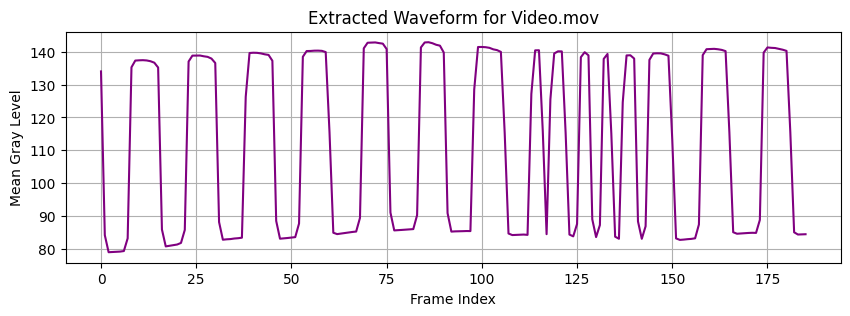

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Video file paths in Drive
drive_folder = '/content/drive/MyDrive/ML'

# List your video files in order matching your experimental matrix:
# (e.g., 4 distances x 2 alpha levels = 8 videos total)
video_files = [
    'Video.mov',    # Dist: 20cm,  Delta Alpha: 0.5
    'Video_1.mov',  # Dist: 40cm,  Delta Alpha: 0.5
    'Video_2.mov',  # Dist: 80cm,  Delta Alpha: 0.5
    'Video_3.mov',  # Dist: 120cm, Delta Alpha: 0.5
    'Video_4.mov',  # Dist: 20cm,  Delta Alpha: 0.1
    'Video_5.mov',  # Dist: 40cm,  Delta Alpha: 0.1
    'Video_6.mov',  # Dist: 80cm,  Delta Alpha: 0.1
    'Video_7.mov'   # Dist: 120cm, Delta Alpha: 0.1
]

distances = [20, 40, 80, 120]
transmitted_text = "HELLO"
transmitted_bits = ''.join(format(ord(c), '08b') for c in transmitted_text)

# Helper function to compute brightness waveform per video
def extract_brightness(video_path):
    cap = cv2.VideoCapture(video_path)
    brightness_list = []

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        brightness_list.append(np.mean(gray))

    cap.release()
    return np.array(brightness_list)

# Quick sanity plot for your first video
sample_path = os.path.join(drive_folder, video_files[0])
if os.path.exists(sample_path):
    signal = extract_brightness(sample_path)
    plt.figure(figsize=(10, 3))
    plt.plot(signal, color='purple')
    plt.title(f"Extracted Waveform for {video_files[0]}")
    plt.xlabel("Frame Index")
    plt.ylabel("Mean Gray Level")
    plt.grid(True)
    plt.show()
else:
    print(f"Could not find {sample_path}. Please check the folder path in Drive.")

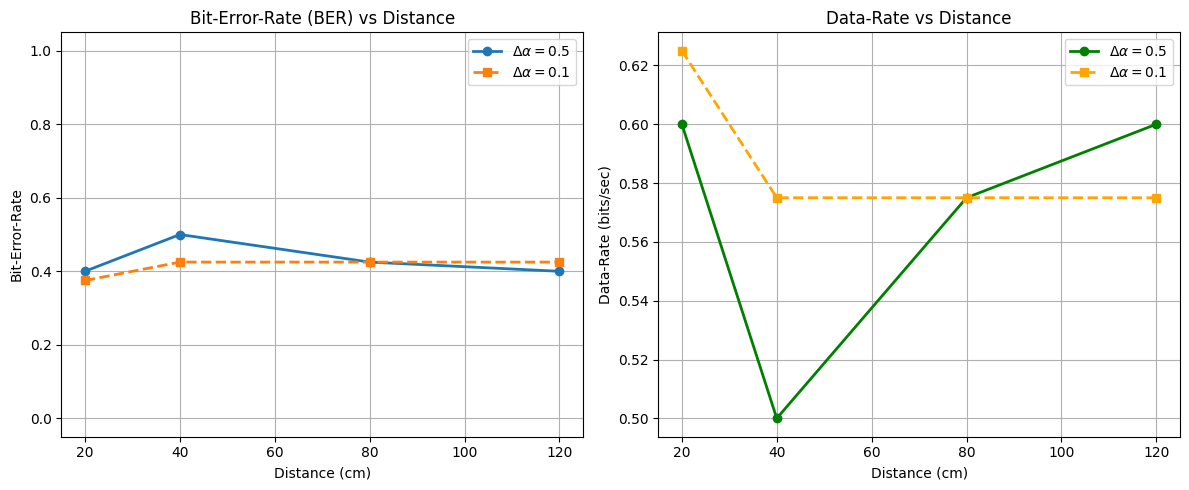

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

drive_folder = '/content/drive/MyDrive/ML'

# Matrix setup matching your 8 recorded files
video_files_delta_05 = ['Video.mov', 'Video_1.mov', 'Video_2.mov', 'Video_3.mov']
video_files_delta_01 = ['Video_4.mov', 'Video_5.mov', 'Video_6.mov', 'Video_7.mov']
distances = [20, 40, 80, 120]

# Sent message parameters
transmitted_text = "HELLO"
transmitted_bits = np.array([int(b) for b in ''.join(format(ord(c), '08b') for c in transmitted_text)])
num_bits = len(transmitted_bits)
bit_duration = 1.0  # 1 second per bit
f0, f1 = 2.0, 5.0   # 2Hz for 0, 5Hz for 1

def analyze_video(file_name):
    path = os.path.join(drive_folder, file_name)
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0

    brightness = []
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        brightness.append(np.mean(gray))
    cap.release()

    signal = np.array(brightness)
    total_time = len(signal) / fps

    # Simple FFT per bit period to decode 2Hz vs 5Hz
    frames_per_bit = int(fps * bit_duration)
    decoded_bits = []

    for i in range(num_bits):
        start_idx = i * frames_per_bit
        end_idx = min((i + 1) * frames_per_bit, len(signal))
        segment = signal[start_idx:end_idx]

        if len(segment) < 2:
            decoded_bits.append(0)
            continue

        # Compute FFT power at f0 (2Hz) vs f1 (5Hz)
        fft_vals = np.abs(np.fft.rfft(segment - np.mean(segment)))
        freqs = np.fft.rfftfreq(len(segment), d=1/fps)

        power_f0 = fft_vals[np.argmin(np.abs(freqs - f0))]
        power_f1 = fft_vals[np.argmin(np.abs(freqs - f1))]

        decoded_bits.append(1 if power_f1 > power_f0 else 0)

    decoded_bits = np.array(decoded_bits[:len(transmitted_bits)])

    # Calculate Metrics according to assignment specs
    correct_bits = np.sum(decoded_bits == transmitted_bits)
    ber = 1.0 - (correct_bits / num_bits)
    data_rate = correct_bits / (num_bits * bit_duration) # bits per second

    return ber, data_rate

# Compute metrics across distances
ber_05, dr_05 = zip(*[analyze_video(f) for f in video_files_delta_05])
ber_01, dr_01 = zip(*[analyze_video(f) for f in video_files_delta_01])

# =========================================================================
# Plot Deliverables for Report
# =========================================================================
plt.figure(figsize=(12, 5))

# Plot 1: Bit Error Rate vs Distance
plt.subplot(1, 2, 1)
plt.plot(distances, ber_05, 'o-', label=r'$\Delta\alpha = 0.5$', linewidth=2)
plt.plot(distances, ber_01, 's--', label=r'$\Delta\alpha = 0.1$', linewidth=2)
plt.title('Bit-Error-Rate (BER) vs Distance')
plt.xlabel('Distance (cm)')
plt.ylabel('Bit-Error-Rate')
plt.ylim(-0.05, 1.05)
plt.grid(True)
plt.legend()

# Plot 2: Data Rate vs Distance
plt.subplot(1, 2, 2)
plt.plot(distances, dr_05, 'o-', color='green', label=r'$\Delta\alpha = 0.5$', linewidth=2)
plt.plot(distances, dr_01, 's--', color='orange', label=r'$\Delta\alpha = 0.1$', linewidth=2)
plt.title('Data-Rate vs Distance')
plt.xlabel('Distance (cm)')
plt.ylabel('Data-Rate (bits/sec)')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()